[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_18/MFM_ch18_srisk_sim/MFM_ch18_srisk_sim.ipynb)

# MFM_ch18_srisk_sim

SRISK as in Brownlees and Engle (2017): GJR-GARCH(1,1) and DCC(1,1) for each bank and its market, LRMES by simulation with resampled standardised innovations (22 days, market fall of 10%; and six months, fall of 40%), compared with the shortcut 1 - exp(-18 MES) and with Normal innovations; break-even leverage.

*Modelling Financial Markets (MFM), Chapter 18: Systemic Risk and Networks. Author: Daniel Traian Pele.*

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [1]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_18'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


In [2]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from scipy.stats import spearmanr
import statsmodels.api as sm
from statsmodels.regression.quantile_regression import QuantReg
from sklearn.linear_model import QuantileRegressor, ElasticNetCV
from scipy import optimize
try:
    from arch import arch_model
except ImportError:                      # Colab: the arch package is not preinstalled
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'arch'])
    from arch import arch_model
import warnings
warnings.filterwarnings('ignore')

Matplotlib is building the font cache; this may take a moment.


## Style and helpers

In [3]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Course colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Teal     = '#17A2B8'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
REGION_COL = {'US': MainBlue, 'EU': IDAred, 'RO': Forest}
REGION_LAB = {'US': 'US banks', 'EU': 'European banks', 'RO': 'Romanian banks (BVB)'}
EVENTS = [('2011-08-08', 'Euro crisis'), ('2016-06-24', 'Brexit vote'), ('2018-12-19', 'RO bank tax'),
          ('2020-03-16', 'COVID-19'), ('2023-03-13', 'SVB'), ('2025-04-07', 'Tariffs')]

HERE = '.'
SEED = 42
B_BOOT = 999
RESULTS = {}


def save_fig(name):
    """Save the figure as transparent PDF and PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def jsonable(x):
    if isinstance(x, dict):
        return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [jsonable(v) for v in x]
    if isinstance(x, np.ndarray):
        return [jsonable(v) for v in x.tolist()]
    if isinstance(x, (np.floating, np.integer)):
        return x.item()
    if isinstance(x, pd.Timestamp):
        return str(x.date())
    return x


def mark_events(ax, ymax=None):
    """Vertical reference lines for events, with black labels."""
    for d, lab in EVENTS:
        t = pd.Timestamp(d)
        if ax.get_xlim()[0] <= mdates.date2num(t) <= ax.get_xlim()[1]:
            ax.axvline(t, color=Gray, lw=0.5, ls=':')
            ax.text(t, ax.get_ylim()[1] if ymax is None else ymax, lab, rotation=90, fontsize=6.5, color='black',
                    ha='right', va='top')

## Data

In [4]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
START = '2010-01-01'
END = '2026-09-18'

# bank -> (symbol, name, region)
BANKS = {
    'JPM':  ('JPM.US',    'JPMorgan Chase',       'US'),
    'BAC':  ('BAC.US',    'Bank of America',      'US'),
    'C':    ('C.US',      'Citigroup',            'US'),
    'GS':   ('GS.US',     'Goldman Sachs',        'US'),
    'MS':   ('MS.US',     'Morgan Stanley',       'US'),
    'WFC':  ('WFC.US',    'Wells Fargo',          'US'),
    'DBK':  ('DBK.XETRA', 'Deutsche Bank',        'EU'),
    'BNP':  ('BNP.PA',    'BNP Paribas',          'EU'),
    'SAN':  ('SAN.MC',    'Santander',            'EU'),
    'INGA': ('INGA.AS',   'ING',                  'EU'),
    'HSBA': ('HSBA.LSE',  'HSBC',                 'EU'),
    'TLV':  ('TLV.RO',    'Banca Transilvania',   'RO'),
    'BRD':  ('BRD.RO',    'BRD-Groupe SG',        'RO'),
}
US = [k for k, v in BANKS.items() if v[2] == 'US']
EU = [k for k, v in BANKS.items() if v[2] == 'EU']
RO = [k for k, v in BANKS.items() if v[2] == 'RO']
ALL = US + EU + RO
NAMES = {k: v[1] for k, v in BANKS.items()}
INDICES = {'SPX': ('GSPC.INDX', 'S&P 500'), 'SX5E': ('STOXX50E.INDX', 'Euro Stoxx 50'),
           'BET': ('BET', 'BET'), 'VIX': ('VIX.INDX', 'VIX')}
REGION_INDEX = {'US': 'SPX', 'EU': 'SX5E', 'RO': 'BET'}


def read_market(symbol):
    """Read the daily price series of one symbol from the course data."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def bank_frame(key, start=START, end=END):
    """Daily prices and volume of one bank, with the adjusted price and the corrections above."""
    symbol, _, region = BANKS[key]
    d = read_market(symbol).loc[start:end].copy()
    d = d[(d.index.dayofweek < 5) & (d['adjusted_close'] > 0)]
    if region == 'RO':
        d = d[d['volume'] > 0]                                   # days without trades
    if key == 'TLV' and pd.Timestamp('2016-05-30') in d.index:
        # bonus-share adjustment: the post-ex-date factor also applies on 30 May 2016
        f = d.loc['2016-05-31', 'adjusted_close'] / d.loc['2016-05-31', 'close']
        d.loc['2016-05-30', 'adjusted_close'] = d.loc['2016-05-30', 'close'] * f
    return d


def bank_price(key, start=START, end=END):
    return bank_frame(key, start, end)['adjusted_close'].rename(key)


def index_close(key, start=START, end=END):
    s = read_market(INDICES[key][0])['close'].loc[start:end]
    s = s[(s.index.dayofweek < 5) & (s > 0)].dropna()
    if key != 'VIX':
        s = s[s.diff() != 0]                                     # holidays filled with the previous price
    return s.rename(key)


def prices(keys, start=START, end=END):
    """Daily prices of banks and/or indices, on common trading days only."""
    cols = [bank_price(k, start, end) if k in BANKS else index_close(k, start, end) for k in keys]
    return pd.concat(cols, axis=1, join='inner').dropna()


def joint_returns(keys, start=START, end=END):
    """Daily log returns in %: prices are aligned on common trading days first, then returns are computed."""
    return 100 * np.log(prices(keys, start, end)).diff().dropna()


def bank_range_vol(keys, start=START, end=END):
    """Daily Parkinson volatility (in %, annualised), on the days common to all banks."""
    out = []
    for k in keys:
        d = bank_frame(k, start, end)
        rng = np.log(d['high'] / d['low']).where(d['high'] > d['low'])
        s2 = rng ** 2 / (4 * np.log(2))
        floor = s2.where(s2 > 0).cummin().ffill()                  # smallest positive value observed UP TO day t
        s2 = s2.fillna(floor)                                     # days with high = low: no look-ahead bias
        out.append((100 * np.sqrt(252 * s2)).rename(k))
    return pd.concat(out, axis=1, join='inner').dropna()


def system_return(R, members):
    """System return: equal-weighted portfolio of the banks (log returns in %, daily approximation)."""
    return R[members].mean(axis=1)


# daily log returns in % (common days) and log Parkinson volatility
R = joint_returns(ALL + ['SPX', 'SX5E', 'BET', 'VIX'])
V = np.log(bank_range_vol(ALL))
print(R.index[0].date(), '->', R.index[-1].date(), len(R), 'common days')


def system_ex(k, members):
    """Return of the regional system without bank k (equal-weighted portfolio)."""
    return R[[j for j in members if j != k]].mean(axis=1)


def region_of(k):
    return BANKS[k][2]

2010-01-05 -> 2026-09-18 3960 common days


## Systemic risk measures

In [5]:
def mes(r_i, r_m, alpha=0.05):
    """MES (%): average loss of the bank on the days when the market is in its alpha-probability tail."""
    q = np.quantile(r_m, alpha)
    return -np.mean(np.asarray(r_i)[np.asarray(r_m) <= q])


def mes_threshold(r_i, r_m, c=-2.0):
    """MES (%) on the days when the market falls by more than |c|% (the definition used for LRMES)."""
    return -np.mean(np.asarray(r_i)[np.asarray(r_m) < c])


def lrmes(mes2_pct):
    """Long-run loss in a crisis (market -40% over six months): LRMES = 1 - exp(-18 MES), MES as a fraction."""
    return 1 - np.exp(-18 * mes2_pct / 100)


def srisk_ratio(lrm, leverage, k=0.08):
    """SRISK / market equity W: k(L - 1) - (1 - k)(1 - LRMES), with L = (D + W)/W."""
    return k * (leverage - 1) - (1 - k) * (1 - lrm)


def breakeven_leverage(lrm, k=0.08):
    """Leverage L* above which SRISK > 0: L* = 1 + (1 - k)(1 - LRMES)/k."""
    return 1 + (1 - k) * (1 - lrm) / k


def qreg(y, X, q):
    """Quantile regression (Koenker-Bassett); returns the coefficients [intercept, slopes]."""
    return QuantReg(np.asarray(y), sm.add_constant(np.asarray(X), has_constant='add')).fit(q=q, max_iter=5000).params


def covar_static(x_sys, x_i, alpha=0.01):
    """Unconditional CoVaR and Delta-CoVaR (%, positive = losses).

    Quantile regression at level alpha: X_sys = a + b X_i;
    CoVaR_alpha = -(a + b q_alpha(X_i)); Delta-CoVaR = b (q_50(X_i) - q_alpha(X_i))."""
    x_sys, x_i = np.asarray(x_sys), np.asarray(x_i)
    a, b = qreg(x_sys, x_i, alpha)
    qa, qm = np.quantile(x_i, alpha), np.quantile(x_i, 0.5)
    return {'a': a, 'b': b, 'var_i': -qa, 'covar': -(a + b * qa), 'covar_med': -(a + b * qm),
            'dcovar': b * (qm - qa), 'var_sys': -np.quantile(x_sys, alpha)}


def block_bootstrap_idx(n, block=20, rng=None):
    """Indices for the moving-block bootstrap (Künsch), fixed-length blocks."""
    rng = rng or np.random.default_rng(0)
    starts = rng.integers(0, n - block + 1, size=int(np.ceil(n / block)))
    return (starts[:, None] + np.arange(block)[None, :]).ravel()[:n]


def covar_boot(x_sys, x_i, alpha=0.01, B=200, block=20, seed=0):
    """95% percentile interval for Delta-CoVaR by moving-block bootstrap."""
    x_sys, x_i = np.asarray(x_sys), np.asarray(x_i)
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(B):
        idx = block_bootstrap_idx(len(x_i), block, rng)
        d.append(covar_static(x_sys[idx], x_i[idx], alpha)['dcovar'])
    return np.percentile(d, [2.5, 97.5])


def covar_dynamic(x_sys, x_i, M, alpha=0.01):
    """Time-varying Delta-CoVaR with state variables M_{t-1} (Adrian & Brunnermeier, 2016).

    X_i,t = a + c'M_{t-1} at levels alpha and 50%  ->  VaR_i,t;
    X_sys,t = a + b X_i,t + c'M_{t-1} at level alpha  ->  Delta-CoVaR_t = b (q50_i,t - qalpha_i,t)."""
    ci_a = qreg(x_i, M, alpha)
    ci_m = qreg(x_i, M, 0.5)
    cs = qreg(x_sys, np.column_stack([x_i, M]), alpha)
    Mc = sm.add_constant(np.asarray(M), has_constant='add')
    qa, qm = Mc @ ci_a, Mc @ ci_m
    return pd.DataFrame({'var_i': -qa, 'dcovar': cs[1] * (qm - qa)}, index=getattr(x_i, 'index', None)), cs[1]


def var_fit(Y, p):
    """VAR(p) estimated by OLS; returns the coefficients A_1..A_p (k x k) and the residual covariance matrix."""
    Y = np.asarray(Y, float)
    T, k = Y.shape
    X = np.hstack([np.ones((T - p, 1))] + [Y[p - l - 1:T - l - 1] for l in range(p)])
    Yt = Y[p:]
    B = np.linalg.lstsq(X, Yt, rcond=None)[0]
    E = Yt - X @ B
    S = E.T @ E / (len(Yt) - X.shape[1])
    A = [B[1 + l * k:1 + (l + 1) * k].T for l in range(p)]
    return A, S


def var_bic(Y, pmax=5):
    """VAR order chosen by the Bayesian information criterion (BIC, Schwarz), with the maximum-likelihood residual covariance matrix."""
    Y = np.asarray(Y, float)
    T, k = Y.shape
    best = None
    n = T - pmax
    for p in range(1, pmax + 1):
        A, S = var_fit(Y[pmax - p:], p)
        S_ml = S * (n - 1 - p * k) / n                        # maximum-likelihood covariance E'E / n
        bic = np.log(np.linalg.det(S_ml)) + np.log(n) * p * k * k / n
        if best is None or bic < best[1]:
            best = (p, bic)
    return best[0]


def ma_coefs(A, H):
    """Moving-average coefficients Phi_0..Phi_{H-1}."""
    k = A[0].shape[0]
    Phi = [np.eye(k)]
    for h in range(1, H):
        Phi.append(sum(A[l] @ Phi[h - l - 1] for l in range(min(h, len(A)))))
    return Phi


def gfevd(A, S, H=10):
    """Generalized forecast error variance decomposition (Pesaran-Shin), rows normalised."""
    Phi = ma_coefs(A, H)
    k = S.shape[0]
    num = np.zeros((k, k))
    den = np.zeros(k)
    for P in Phi:
        PS = P @ S
        num += PS ** 2
        den += np.diag(P @ S @ P.T)
    theta = num / np.diag(S)[None, :] / den[:, None]
    return theta / theta.sum(axis=1, keepdims=True)


def spillover_table(theta, names):
    """Connectedness table: contributions (%), FROM, TO, NET and the total index."""
    k = theta.shape[0]
    D = 100 * theta
    off = D - np.diag(np.diag(D))
    frm, to = off.sum(axis=1), off.sum(axis=0)
    tab = pd.DataFrame(D, index=names, columns=names)
    return {'table': tab, 'from': pd.Series(frm, index=names), 'to': pd.Series(to, index=names),
            'net': pd.Series(to - frm, index=names), 'total': off.sum() / k,
            'pairwise_net': pd.DataFrame(off.T - off, index=names, columns=names)}


def rolling_total(Y, window=250, step=5, p=2, H=10):
    """Total connectedness index on rolling windows."""
    Y = pd.DataFrame(Y)
    out, frm_to = {}, {}
    for end in range(window, len(Y) + 1, step):
        w = Y.iloc[end - window:end]
        A, S = var_fit(w.values, p)
        st = spillover_table(gfevd(A, S, H), list(Y.columns))
        out[Y.index[end - 1]] = st['total']
        frm_to[Y.index[end - 1]] = st['net']
    return pd.Series(out), pd.DataFrame(frm_to).T


def check_loss(u, tau):
    return u * (tau - (u < 0))


def lasso_qr_gacv(y, X, tau=0.05, lambdas=None):
    """L1-penalized quantile regression; lambda chosen by the generalized approximate cross-validation criterion GACV = sum rho_tau(res) / (n - df)."""
    y, X = np.asarray(y, float), np.asarray(X, float)
    n = len(y)
    lambdas = np.logspace(-4, -0.5, 15) if lambdas is None else lambdas
    rows = []
    for lam in lambdas:
        m = QuantileRegressor(quantile=tau, alpha=lam, solver='highs').fit(X, y)
        res = y - m.predict(X)
        df = int(np.sum(np.abs(m.coef_) > 1e-8))
        g = check_loss(res, tau).sum() / max(n - df, 1)
        rows.append((lam, g, df, m.coef_.copy()))
    i = int(np.argmin([r[1] for r in rows]))
    return {'lambda': rows[i][0], 'gacv': [r[1] for r in rows], 'df': [r[2] for r in rows],
            'lambdas': list(lambdas), 'coef': rows[i][3], 'df_sel': rows[i][2]}

## Helper functions

In [6]:
B = 999

## Analysis

In [7]:
def gjr_fit(r):
    """GJR-GARCH(1,1) with zero mean (log returns in %), quasi-maximum likelihood (QML)."""
    m = arch_model(r, mean='Zero', vol='GARCH', p=1, o=1, q=1, dist='normal', rescale=False).fit(disp='off')
    om, a, g, b = m.params[['omega', 'alpha[1]', 'gamma[1]', 'beta[1]']]
    s2 = m.conditional_volatility ** 2
    s2_next = om + (a + g * (r[-1] < 0)) * r[-1] ** 2 + b * s2[-1]
    return {'omega': om, 'alpha': a, 'gamma': g, 'beta': b, 'sig': np.sqrt(s2), 's2_next': s2_next}


def dcc_fit(e):
    """Bivariate DCC(1,1), second QML step (Engle, 2002); e = standardised residuals T x 2."""
    S = np.corrcoef(e.T)
    T = len(e)

    def filt(a, b):
        Q = S.copy()
        rho = np.empty(T)
        for t in range(T):
            rho[t] = Q[0, 1] / np.sqrt(Q[0, 0] * Q[1, 1])
            Q = (1 - a - b) * S + a * np.outer(e[t], e[t]) + b * Q
        return rho, Q

    def nll(th):
        a, b = th
        if a <= 0 or b <= 0 or a + b >= 0.999:
            return 1e10
        rho, _ = filt(a, b)
        z1, z2 = e[:, 0], e[:, 1]
        return 0.5 * np.sum(np.log(1 - rho ** 2) + (z1 ** 2 + z2 ** 2 - 2 * rho * z1 * z2) / (1 - rho ** 2)
                            - (z1 ** 2 + z2 ** 2))

    best = min((optimize.minimize(nll, x0, method='Nelder-Mead', options={'xatol': 1e-5, 'fatol': 1e-4})
                for x0 in [(0.02, 0.95), (0.05, 0.90)]), key=lambda o: o.fun)
    a, b = best.x
    rho, Q = filt(a, b)
    return {'a': a, 'b': b, 'S': S, 'rho': rho, 'Q_next': Q}


def simulate_market(gm, eps_m, idx):
    """Market paths (GJR) from the resampled innovations eps_m[idx], idx: S x h."""
    Sn, h = idx.shape
    s2 = np.full(Sn, gm['s2_next'])
    cum = np.zeros(Sn)
    for t in range(h):
        r = np.sqrt(s2) * eps_m[idx[:, t]]
        cum += r
        s2 = gm['omega'] + (gm['alpha'] + gm['gamma'] * (r < 0)) * r ** 2 + gm['beta'] * s2
    return cum


def simulate_firm(gf, gm, dcc, eps_m, xi, idx):
    """Bank paths conditional on the same drawn dates (Appendix A of Brownlees & Engle, 2017)."""
    Sn, h = idx.shape
    s2i = np.full(Sn, gf['s2_next'])
    q11 = np.full(Sn, dcc['Q_next'][0, 0])
    q22 = np.full(Sn, dcc['Q_next'][1, 1])
    q12 = np.full(Sn, dcc['Q_next'][0, 1])
    cum = np.zeros(Sn)
    a, b, S = dcc['a'], dcc['b'], dcc['S']
    for t in range(h):
        rho = q12 / np.sqrt(q11 * q22)
        em = eps_m[idx[:, t]]
        ei = rho * em + np.sqrt(1 - rho ** 2) * xi[idx[:, t]]
        r = np.sqrt(s2i) * ei
        cum += r
        s2i = gf['omega'] + (gf['alpha'] + gf['gamma'] * (r < 0)) * r ** 2 + gf['beta'] * s2i
        q11 = (1 - a - b) * S[0, 0] + a * ei ** 2 + b * q11
        q22 = (1 - a - b) * S[1, 1] + a * em ** 2 + b * q22
        q12 = (1 - a - b) * S[0, 1] + a * ei * em + b * q12
    return cum


def _sim_gauss_market(gm, eps):
    Sn, h = eps.shape
    s2 = np.full(Sn, gm['s2_next'])
    cum = np.zeros(Sn)
    for t in range(h):
        r = np.sqrt(s2) * eps[:, t]
        cum += r
        s2 = gm['omega'] + (gm['alpha'] + gm['gamma'] * (r < 0)) * r ** 2 + gm['beta'] * s2
    return cum


def _sim_gauss_firm(gf, gm, dcc, eps_m_paths, rng):
    """Variant with Normal innovations (the same crisis paths of the market, xi ~ N(0,1))."""
    Sn, h = eps_m_paths.shape
    xi = rng.standard_normal((Sn, h))
    s2i = np.full(Sn, gf['s2_next'])
    q11, q22, q12 = (np.full(Sn, dcc['Q_next'][i, j]) for i, j in [(0, 0), (1, 1), (0, 1)])
    a, b, S = dcc['a'], dcc['b'], dcc['S']
    cum = np.zeros(Sn)
    for t in range(h):
        rho = q12 / np.sqrt(q11 * q22)
        em = eps_m_paths[:, t]
        ei = rho * em + np.sqrt(1 - rho ** 2) * xi[:, t]
        r = np.sqrt(s2i) * ei
        cum += r
        s2i = gf['omega'] + (gf['alpha'] + gf['gamma'] * (r < 0)) * r ** 2 + gf['beta'] * s2i
        q11 = (1 - a - b) * S[0, 0] + a * ei ** 2 + b * q11
        q22 = (1 - a - b) * S[1, 1] + a * em ** 2 + b * q22
        q12 = (1 - a - b) * S[0, 1] + a * ei * em + b * q12
    return cum


def lrmes_sim(end, h, C, Sn, seed=SEED, gaussian=False):
    """LRMES (fraction) for the 13 banks at date `end`, horizon h days, threshold C (arithmetic market return)."""
    rng = np.random.default_rng(seed)
    Rs = R.loc[:end]
    out, info = {}, {}
    for reg, mem in (('US', US), ('EU', EU), ('RO', RO)):
        rm = Rs[REGION_INDEX[reg]].values
        gm = gjr_fit(rm)
        eps_m = rm / gm['sig']
        T = len(rm)
        # 1) market paths; only the crisis scenarios are kept (algorithm of Appendix A of Brownlees & Engle, 2017)
        keep_idx, n_all = [], 0
        for _ in range(Sn // 20000):
            idx = rng.integers(0, T, size=(20000, h))
            n_all += 20000
            if gaussian:
                eps_draw = rng.standard_normal((20000, h))
                # Gaussian paths: indices into their own matrix of innovations
                cm = _sim_gauss_market(gm, eps_draw)
                keep_idx.append(eps_draw[np.exp(cm / 100) - 1 < C])
            else:
                cm = simulate_market(gm, eps_m, idx)
                keep_idx.append(idx[np.exp(cm / 100) - 1 < C])
        kept = np.concatenate(keep_idx)
        info[reg] = {'p_crisis': len(kept) / n_all, 'n_crisis': len(kept), 'market': gm}
        for k in mem:
            ri = Rs[k].values
            gf = gjr_fit(ri)
            e = np.column_stack([ri / gf['sig'], eps_m])
            dcc = dcc_fit(e)
            xi = (e[:, 0] - dcc['rho'] * e[:, 1]) / np.sqrt(1 - dcc['rho'] ** 2)
            if gaussian:
                ci = _sim_gauss_firm(gf, gm, dcc, kept, rng)
            else:
                ci = simulate_firm(gf, gm, dcc, eps_m, xi, kept)
            Ri = np.exp(ci / 100) - 1
            out[k] = {'lrmes': -Ri.mean(), 'mc_se': Ri.std(ddof=1) / np.sqrt(len(Ri)),
                      'q05': -np.quantile(Ri, 0.95), 'q95': -np.quantile(Ri, 0.05),
                      'rho_last': dcc['rho'][-1], 'dcc_a': dcc['a'], 'dcc_b': dcc['b'],
                      'gjr': [gf['alpha'], gf['gamma'], gf['beta']]}
    return out, info


def srisk_simulation():
    end = R.index[-1]
    be, be_info = lrmes_sim(end, 22, -0.10, 200000, SEED)                 # Brownlees & Engle (2017): h = 22, C = -10%
    v6, v6_info = lrmes_sim(end, 126, -0.40, 400000, SEED + 1)            # the 6-month / -40% scenario
    g6, _ = lrmes_sim(end, 126, -0.40, 400000, SEED + 2, gaussian=True)   # the same, with Normal innovations
    cv, cv_info = lrmes_sim(pd.Timestamp('2020-03-31'), 22, -0.10, 200000, SEED + 3)   # conditional on 31.03.2020
    short = {k: lrmes(mes_threshold(R[k].values, R[REGION_INDEX[region_of(k)]].values, -2.0)) for k in ALL}
    res = {'end': end, 'be': be, 'v6': v6, 'g6': g6, 'covid': cv, 'short': short,
           'p_crisis_be': {r: be_info[r]['p_crisis'] for r in be_info},
           'p_crisis_v6': {r: v6_info[r]['p_crisis'] for r in v6_info},
           'n_crisis_v6': {r: v6_info[r]['n_crisis'] for r in v6_info},
           'p_crisis_covid': {r: cv_info[r]['p_crisis'] for r in cv_info}}
    s = pd.DataFrame({'short': short, 'v6': {k: v['lrmes'] for k, v in v6.items()},
                      'g6': {k: v['lrmes'] for k, v in g6.items()}, 'be': {k: v['lrmes'] for k, v in be.items()}})
    res['spearman_short_v6'] = stats.spearmanr(s['short'], s['v6']).correlation
    res['spearman_v6_g6'] = stats.spearmanr(s['v6'], s['g6']).correlation
    res['ratio_range'] = [float((s['v6'] / s['short']).min()), float((s['v6'] / s['short']).max())]
    res['Lstar_v6'] = {k: breakeven_leverage(v['lrmes']) for k, v in v6.items()}
    res['Lstar_be'] = {k: breakeven_leverage(v['lrmes']) for k, v in be.items()}
    return res, s


def fig_lrmes_models(s):
    fig, ax = plt.subplots(figsize=(7.2, 3.0))
    xs = np.arange(len(ALL))
    w = 0.27
    ax.bar(xs - w, 100 * s.loc[ALL, 'short'], w, color=MainBlue, label='Shortcut 1 - exp(-18 MES), MES at the -2% threshold')
    ax.bar(xs, 100 * s.loc[ALL, 'v6'], w, color=IDAred, label='GJR-GARCH + DCC, resampled innovations')
    ax.bar(xs + w, 100 * s.loc[ALL, 'g6'], w, color=Orange, label='GJR-GARCH + DCC, Normal innovations')
    ax.set_xticks(xs)
    ax.set_xticklabels([NAMES[k] for k in ALL], rotation=35, ha='right', fontsize=7.5)
    ax.set_ylabel('LRMES: 6-month loss given\nmarket fall of 40% (%)')
    legend_outside_bottom(ax, ncol=1, y=-0.42)
    save_fig('ch18_lrmes_models')

## Run

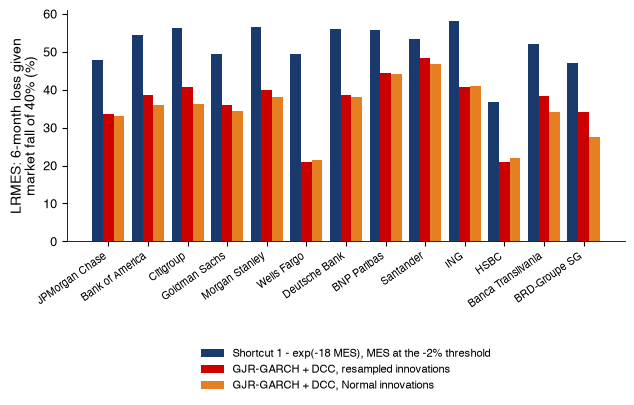

   saved ch18_lrmes_models


,short,v6,g6,be
JPM,47.8,33.5,33.0,10.6
BAC,54.6,38.6,36.0,14.3
C,56.1,40.8,36.3,13.0
GS,49.4,35.9,34.4,16.5
MS,56.4,40.0,38.0,16.3
WFC,49.4,20.8,21.5,6.7
DBK,55.9,38.7,38.2,14.4
BNP,55.8,44.5,44.1,15.6
SAN,53.3,48.2,46.7,16.6
INGA,58.0,40.8,41.1,12.5


In [8]:
sr, s = srisk_simulation()   # several minutes
fig_lrmes_models(s)
(100 * s).round(1)

![ch18_lrmes_models](./ch18_lrmes_models.png)

Output: `ch18_lrmes_models.pdf`